In [1]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
bmadushanirodrigo_fracture_multi_region_x_ray_data_path = kagglehub.dataset_download('bmadushanirodrigo/fracture-multi-region-x-ray-data')

print('Data source import complete.')


Using Colab cache for faster access to the 'fracture-multi-region-x-ray-data' dataset.
Data source import complete.



[🚀] Number of GPUs in Sync: 1

Loading Training Data...
Found 9246 images belonging to 2 classes.
Loading Validation Data...
Found 829 images belonging to 2 classes.
Loading Test Data...
Found 506 images belonging to 2 classes.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     9,470,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,563,713 (36.48 MB)

 Trainable params: 9,563,713 (36.48 MB)

 Non-trainable params: 0 (0.00 B)


[⚡] Starting Accelerated Dual-GPU Training...
Epoch 1/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.6389 - loss: 0.6414

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


73/73 ━━━━━━━━━━━━━━━━━━━━ 588s 8s/step - accuracy: 0.7131 - loss: 0.5591 - val_accuracy: 0.8540 - val_loss: 0.3778
Epoch 2/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 586s 8s/step - accuracy: 0.8652 - loss: 0.3286 - val_accuracy: 0.8999 - val_loss: 0.3318
Epoch 3/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 578s 8s/step - accuracy: 0.9236 - loss: 0.2151 - val_accuracy: 0.9107 - val_loss: 0.3036
Epoch 4/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 589s 8s/step - accuracy: 0.9438 - loss: 0.1585 - val_accuracy: 0.9300 - val_loss: 0.2097
Epoch 5/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 577s 8s/step - accuracy: 0.9604 - loss: 0.1168 - val_accuracy: 0.9312 - val_loss: 0.2684
Epoch 6/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 576s 8s/step - accuracy: 0.9657 - loss: 0.1036 - val_accuracy: 0.9433 - val_loss: 0.2043
Epoch 7/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 578s 8s/step - accuracy: 0.9725 - loss: 0.0781 - val_accuracy: 0.9433 - val_loss: 0.1526
Epoch 8/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 582s 8s/step - accuracy: 0.9763 - loss: 0.0655 - val_accuracy: 0.9566 - val_loss: 0.

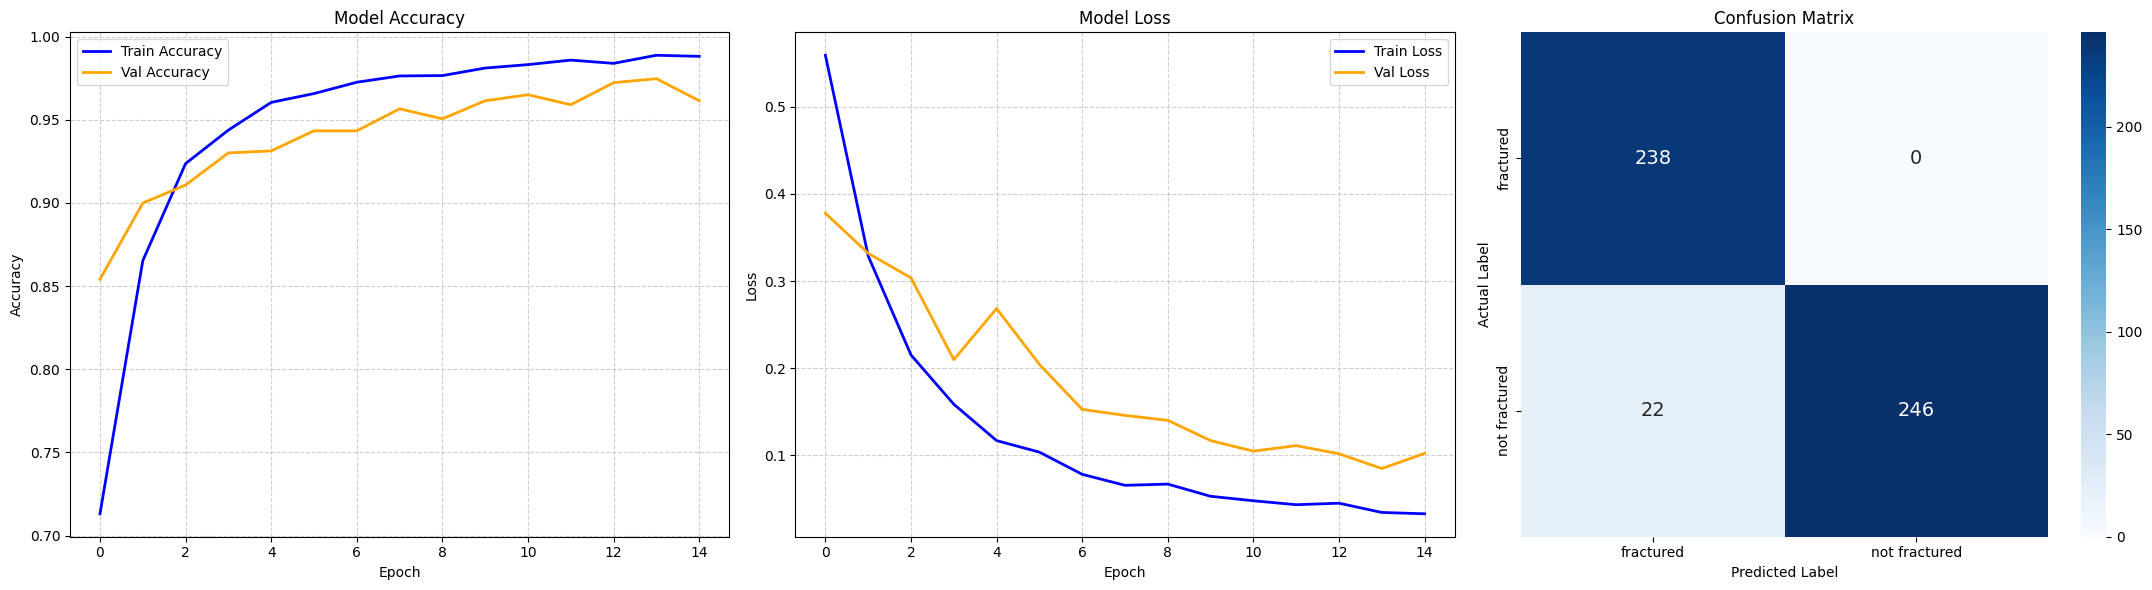


--- TESTING ON 10 RANDOM IMAGES ---


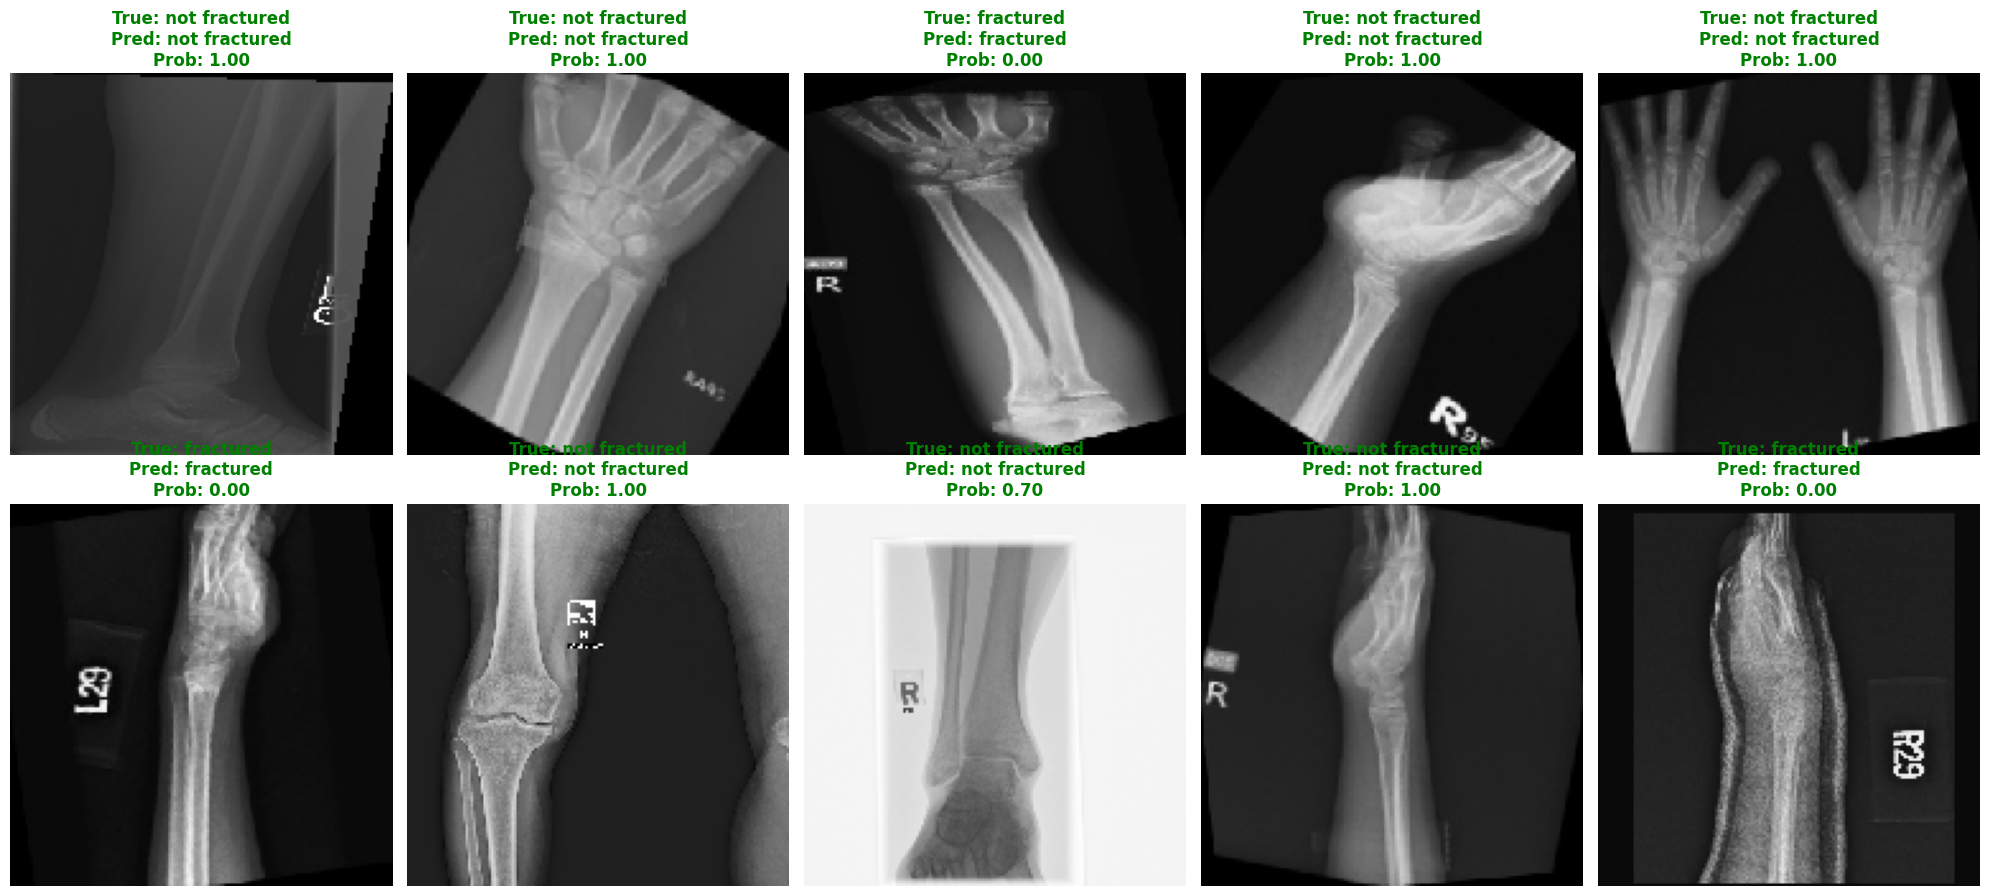

In [2]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from PIL import ImageFile

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array

# ==========================================
# 1. CRITICAL FIX FOR TRUNCATED IMAGES
# ==========================================
ImageFile.LOAD_TRUNCATED_IMAGES = True

# ==========================================
# 2. PATHS CONFIGURATION
# ==========================================
# Pointing to the parent directories. Keras automatically finds the 'fractured' and 'not fractured' subfolders!
train_dir = '/kaggle/input/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/train'
val_dir = '/kaggle/input/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/val'
test_dir = '/kaggle/input/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/test'

# Fallback paths just in case Kaggle mounts it slightly differently
if not os.path.exists(train_dir):
    train_dir = '/kaggle/input/fracture-multi-region-x-ray-data/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/train'
    val_dir = '/kaggle/input/fracture-multi-region-x-ray-data/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/val'
    test_dir = '/kaggle/input/fracture-multi-region-x-ray-data/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/test'

# ==========================================
# 3. DUAL GPU SETUP & HYPERPARAMETERS
# ==========================================
strategy = tf.distribute.MirroredStrategy()
print(f"\n[🚀] Number of GPUs in Sync: {strategy.num_replicas_in_sync}")

img_size = (150, 150)
# HUGE batch size for 2x T4 GPUs (128 per GPU = 256 total)
batch_size = 128 * strategy.num_replicas_in_sync
epochs = 15

# ==========================================
# 4. DATA GENERATORS
# ==========================================
train_datagen = ImageDataGenerator(rescale=1./255, rotation_range=15, zoom_range=0.1, horizontal_flip=True)
val_test_datagen = ImageDataGenerator(rescale=1./255)

print("\nLoading Training Data...")
train_generator = train_datagen.flow_from_directory(
    train_dir, target_size=img_size, batch_size=batch_size, class_mode='binary'
)
print("Loading Validation Data...")
val_generator = val_test_datagen.flow_from_directory(
    val_dir, target_size=img_size, batch_size=batch_size, class_mode='binary'
)
print("Loading Test Data...")
test_generator = val_test_datagen.flow_from_directory(
    test_dir, target_size=img_size, batch_size=batch_size, class_mode='binary', shuffle=False
)

# ==========================================
# 5. BUILD & COMPILE MODEL (INSIDE STRATEGY)
# ==========================================
with strategy.scope():
    model = Sequential([
        tf.keras.layers.Input(shape=(img_size[0], img_size[1], 3)),
        Conv2D(32, (3,3), activation='relu'),
        MaxPooling2D(2,2),
        Conv2D(64, (3,3), activation='relu'),
        MaxPooling2D(2,2),
        Conv2D(128, (3,3), activation='relu'),
        MaxPooling2D(2,2),
        Flatten(),
        Dense(256, activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid') # Binary (fractured vs not fractured)
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model.summary()

# ==========================================
# 6. TRAIN THE MODEL
# ==========================================
print("\n[⚡] Starting Accelerated Dual-GPU Training...")
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=epochs
)

# ==========================================
# 7. SAVE & EVALUATE
# ==========================================
model.save('bone_fracture_cnn_model.keras')
print("\n[+] Model successfully saved as 'bone_fracture_cnn_model.keras'")

test_loss, test_acc = model.evaluate(test_generator, verbose=0)
print(f"\n{'='*40}")
print(f" FINAL TEST ACCURACY : {test_acc*100:.2f}% ")
print(f"{'='*40}")

# ==========================================
# 8. METRICS & REPORTS
# ==========================================
test_generator.reset()
y_pred_probs = model.predict(test_generator)
y_pred = (y_pred_probs > 0.5).astype(int).reshape(-1)
y_true = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(y_true, y_pred, target_names=class_labels))

# ==========================================
# 9. PLOTTING
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# Accuracy Curve
axes[0].plot(history.history['accuracy'], label='Train Accuracy', color='blue', linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy', color='orange', linewidth=2)
axes[0].set_title('Model Accuracy')
axes[0].set_ylabel('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# Loss Curve
axes[1].plot(history.history['loss'], label='Train Loss', color='blue', linewidth=2)
axes[1].plot(history.history['val_loss'], label='Val Loss', color='orange', linewidth=2)
axes[1].set_title('Model Loss')
axes[1].set_ylabel('Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2], xticklabels=class_labels, yticklabels=class_labels, annot_kws={"size": 14})
axes[2].set_title('Confusion Matrix')
axes[2].set_ylabel('Actual Label')
axes[2].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()

# ==========================================
# 10. TEST ON 10 RANDOM IMAGES
# ==========================================
print("\n--- TESTING ON 10 RANDOM IMAGES ---")
all_test_images = []

# This loop automatically detects the 'fractured' and 'not fractured' folders
for class_folder in os.listdir(test_dir):
    class_path = os.path.join(test_dir, class_folder)
    if os.path.isdir(class_path):
        for img_file in os.listdir(class_path):
            all_test_images.append((os.path.join(class_path, img_file), class_folder))

# Grab 10 random images
random_sample = random.sample(all_test_images, 10)
fig, axes = plt.subplots(2, 5, figsize=(20, 9))
axes = axes.flatten()
inv_map = {v: k for k, v in test_generator.class_indices.items()}

for i, (img_path, true_label) in enumerate(random_sample):
    img = load_img(img_path, target_size=img_size)
    img_array = img_to_array(img) / 255.0
    img_array_expanded = np.expand_dims(img_array, axis=0)

    pred_prob = model.predict(img_array_expanded, verbose=0)[0][0]
    pred_class_idx = 1 if pred_prob > 0.5 else 0
    pred_label = inv_map[pred_class_idx]

    axes[i].imshow(img)
    axes[i].axis('off')

    color = 'green' if pred_label == true_label else 'red'
    axes[i].set_title(f"True: {true_label}\nPred: {pred_label}\nProb: {pred_prob:.2f}", color=color, fontweight='bold')

plt.tight_layout()
plt.show()